### Importing necessary libraries

In [2]:
# %pip install pandas, numpy, seaborn, matplotlib, pillow, tqdm, scikit-learn, catboost
# %pip install -U ipywidgets

In [43]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import PIL.Image as Image
import os, random, time
import math
from catboost import CatBoostClassifier, CatBoostRegressor
import tqdm
from tqdm.auto import tqdm

from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [4]:
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
# colors = ["#078533", "#850728", "#fcba03"]
sns.set_palette(sns.color_palette("Set2"))

### Read dataset
This dataset combines two groups from the Mayo Clinic PBC study:

1. Randomized clinical trial patients (312)
* Full clinical workup
* Lab tests and physical findings recorded
* Assigned Drug = D-penicillamine or Placebo

2. Observational follow-up patients (106)
* Did not participate in the drug trial
* Only basic demographics and survival tracked
* No drug assignment
* Many labs and clinical signs not measured

In [51]:
DATA_PATH = [
                "./data/raw/1_differentiated_thyroid_cancer_recurrence.csv",
                "./data/raw/2_cirrhosis_patient_survival_prediction.csv",
                "./data/raw/3_glioma_grading_clinical_and_mutation_features.csv",
                "./data/raw/5_beed_bangalore_eeg_epilepsy_dataset",
                "./data/raw/6_cdc_diabetes_health_indicators"
]

# DATA_PATH = "./data/raw/2_cirrhosis_patient_survival_prediction.csv"

df = pd.read_csv(DATA_PATH[1]).drop(columns=["ID"])
df_raw = df.copy()
print("Data frame shape:", df.shape)

Data frame shape: (418, 19)


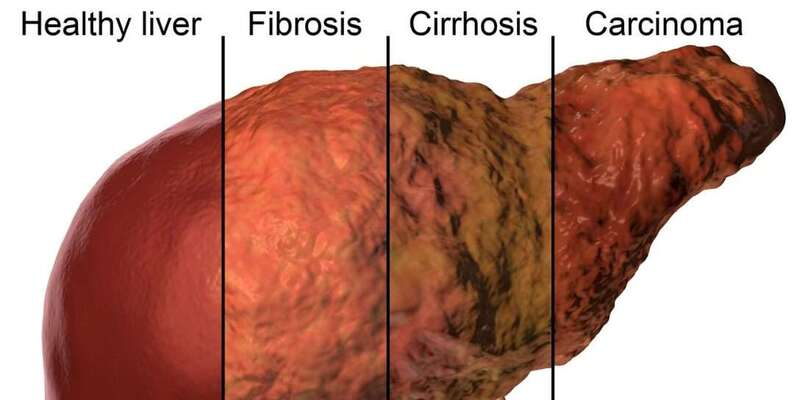

In [6]:
image = Image.open('./images/2_cirrhosis_patient_survival_prediction-dataset-cover.jpg')
display(image)

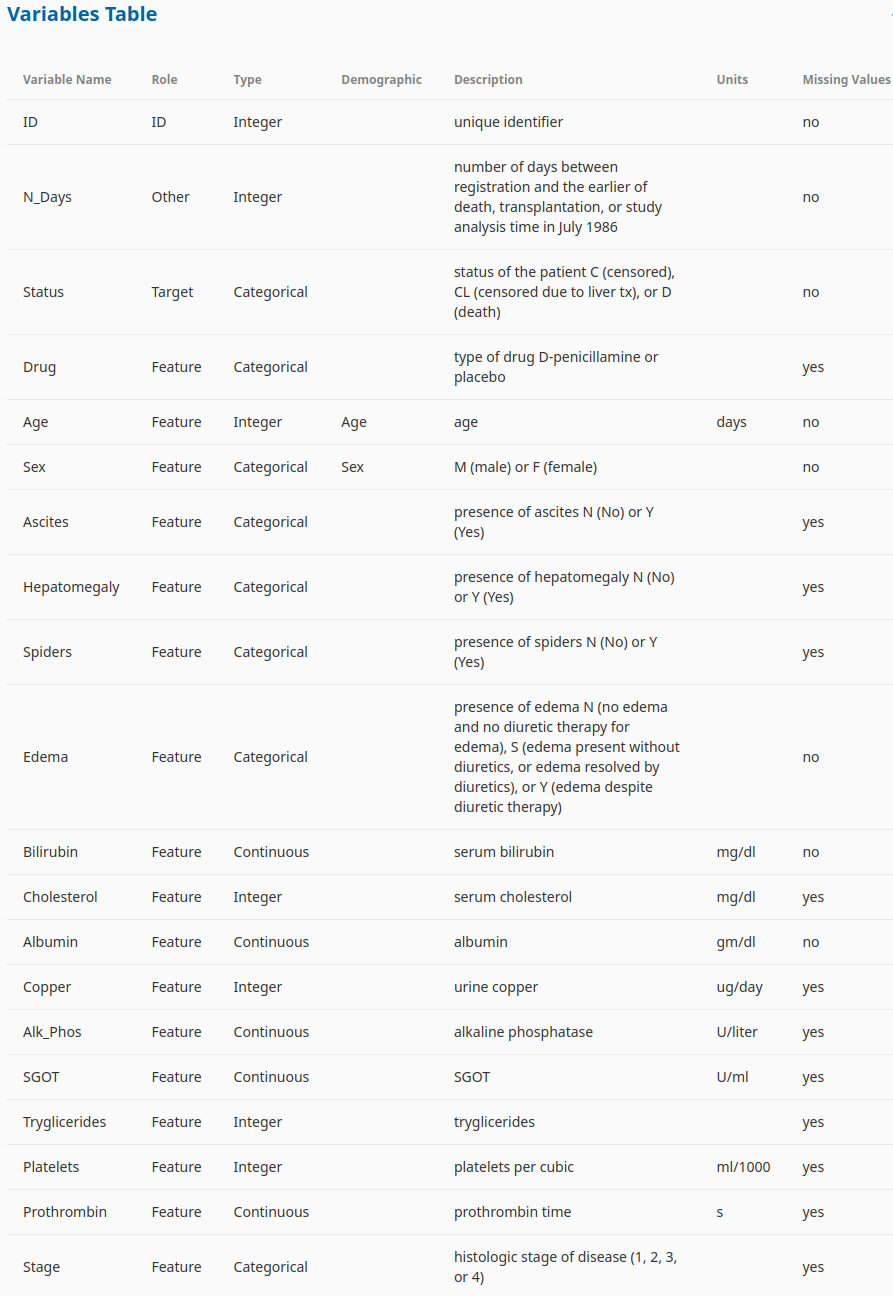

In [7]:
image = Image.open('./images/2_cirrhosis_patient_survival_prediction_variables_table.png')
display(image)

Medical defenition of the features

Let us take a look at what each feature indicates:

* N_Days: Number of days betwqeen registration and the earlier of death, transplantation, or study analysis time in July 1986
* Drug: Type of drug administered to the patient, with options such as D-penicillamine or Placebo.
* Age: Age of the patient, indicating the chronological age at the time of data collection.
* Sex: Gender of the patient, with "F" representing females.
* Ascites: Presence or absence of ascites, a medical condition characterized by fluid accumulation in the abdomen.
* Hepatomegaly: Presence or absence of hepatomegaly, an enlargement of the liver.
* Spiders: Presence or absence of spider angiomas, visible blood vessels in a spider-like pattern on the skin.
* Edema: Presence or absence of edema, which is swelling caused by the accumulation of excess fluid in body tissues.
* Bilirubin: Bilirubin levels in the blood, an indicator of liver function.
* Cholesterol: Cholesterol levels in the blood, a measure of lipid metabolism.
* Albumin: Albumin levels in the blood, an important protein produced by the liver.
* Copper: Copper levels, which can be relevant to liver function
* Alk_Phos: Alkaline phosphatase levels in the blood, an enzyme associated with liver and bone function.
* SGOT: Serum Glutamic Oxaloacetic Transaminase levels, an enzyme indicating liver health.
* Tryglicerides: Triglycerides levels in the blood, representing another aspect of lipid metabolism.
* Platelets: Platelet count in the blood, important for blood clotting.
* Prothrombin: Prothrombin levels, a key component in the blood clotting process.
* Stage: Stage of the patient's condition, providing information on the severity or progression of cirrhosis.

In [8]:
# Head 
display(df.head())

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [9]:
# Tail 
display(df.tail())

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
413,681,D,NaN,24472,F,NaN,NaN,NaN,N,1.2,NaN,2.96,NaN,NaN,NaN,NaN,174.0,10.9,3.0
414,1103,C,NaN,14245,F,NaN,NaN,NaN,N,0.9,NaN,3.83,NaN,NaN,NaN,NaN,180.0,11.2,4.0
415,1055,C,NaN,20819,F,NaN,NaN,NaN,N,1.6,NaN,3.42,NaN,NaN,NaN,NaN,143.0,9.9,3.0
416,691,C,NaN,21185,F,NaN,NaN,NaN,N,0.8,NaN,3.75,NaN,NaN,NaN,NaN,269.0,10.4,3.0
417,976,C,NaN,19358,F,NaN,NaN,NaN,N,0.7,NaN,3.29,NaN,NaN,NaN,NaN,350.0,10.6,4.0


### Sanity check of the dataset

In [10]:
# Dataset information
print("Dataframe info:")
df.info()

Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         418 non-null    int64  
 1   Status         418 non-null    str    
 2   Drug           312 non-null    str    
 3   Age            418 non-null    int64  
 4   Sex            418 non-null    str    
 5   Ascites        312 non-null    str    
 6   Hepatomegaly   312 non-null    str    
 7   Spiders        312 non-null    str    
 8   Edema          418 non-null    str    
 9   Bilirubin      418 non-null    float64
 10  Cholesterol    284 non-null    float64
 11  Albumin        418 non-null    float64
 12  Copper         310 non-null    float64
 13  Alk_Phos       312 non-null    float64
 14  SGOT           312 non-null    float64
 15  Tryglicerides  282 non-null    float64
 16  Platelets      407 non-null    float64
 17  Prothrombin    416 non-null    float64
 18  Stage

In [11]:
# Finding missing values
df.isnull().sum()

N_Days             0
Status             0
Drug             106
Age                0
Sex                0
Ascites          106
Hepatomegaly     106
Spiders          106
Edema              0
Bilirubin          0
Cholesterol      134
Albumin            0
Copper           108
Alk_Phos         106
SGOT             106
Tryglicerides    136
Platelets         11
Prothrombin        2
Stage              6
dtype: int64

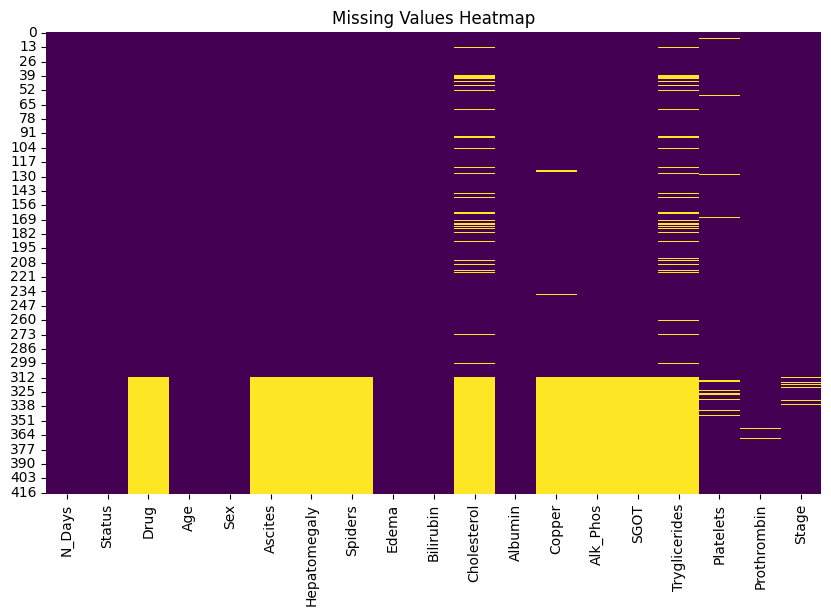

In [12]:
# Missing value visualization
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

The cirrhosis dataset combines two different patient groups from the Mayo Clinic PBC study (1974–1984):

1. 312 patients who participated in the randomized clinical trial (placebo vs D-penicillamine), and
2. 106 additional patients who did not enroll in the trial but agreed to provide only basic information and be followed for survival.

The 106 non-trial patients have many null values because their data collection was limited by design. Unlike trial participants—who underwent a structured protocol 
with regular lab tests and detailed clinical measurements—the non-trial group typically had only minimal baseline records available. As a result, many of the 
biochemical and clinical measurements (e.g., cholesterol, copper, alkaline phosphatase, SGOT, triglycerides, platelets, prothrombin, etc.) were not measured, 
not recorded, or not required for these patients, so those fields appear as missing (NA).

In [13]:
# Finding duplicate values
df.duplicated().sum()

np.int64(0)

In [14]:
# Identifying garbage values in categorical (object) columns
categorical_columns = df.select_dtypes(include=['object']).columns
for col in categorical_columns:
    print(f"Unique values in column '{col}': {df[col].unique()}")   

Unique values in column 'Status': <StringArray>
['D', 'C', 'CL']
Length: 3, dtype: str
Unique values in column 'Drug': <StringArray>
['D-penicillamine', 'Placebo', nan]
Length: 3, dtype: str
Unique values in column 'Sex': <StringArray>
['F', 'M']
Length: 2, dtype: str
Unique values in column 'Ascites': <StringArray>
['Y', 'N', nan]
Length: 3, dtype: str
Unique values in column 'Hepatomegaly': <StringArray>
['Y', 'N', nan]
Length: 3, dtype: str
Unique values in column 'Spiders': <StringArray>
['Y', 'N', nan]
Length: 3, dtype: str
Unique values in column 'Edema': <StringArray>
['Y', 'N', 'S']
Length: 3, dtype: str


C:\Users\Jonayed\AppData\Local\Temp\ipykernel_4504\3947895639.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


# Exploratory Data Analysis (EDA)

In [15]:
LABEL = "Status"
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
NUM_FEATS = [x for x in df.columns if x not in CAT_FEATS and x != LABEL]
INP_FEATS = df.drop(LABEL, axis=1).columns.tolist() # original feats

# Descriptive statistics 
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
N_Days,418.0,1917.782297,1104.672992,41.00,1092.7500,1730.00,2613.50,4795.00
Age,418.0,18533.351675,3815.845055,9598.00,15644.5000,18628.00,21272.50,28650.00
Bilirubin,418.0,3.220813,4.407506,0.30,0.8000,1.40,3.40,28.00
Cholesterol,284.0,369.510563,231.944545,120.00,249.5000,309.50,400.00,1775.00
Albumin,418.0,3.497440,0.424972,1.96,3.2425,3.53,3.77,4.64
Copper,310.0,97.648387,85.613920,4.00,41.2500,73.00,123.00,588.00
Alk_Phos,312.0,1982.655769,2140.388824,289.00,871.5000,1259.00,1980.00,13862.40
SGOT,312.0,122.556346,56.699525,26.35,80.6000,114.70,151.90,457.25
Tryglicerides,282.0,124.702128,65.148639,33.00,84.2500,108.00,151.00,598.00
Platelets,407.0,257.024570,98.325585,62.00,188.5000,251.00,318.00,721.00


In [16]:
# Descriptive statistics for categorical columns
df.describe(include=['object', 'string']).T

,count,unique,top,freq
Status,418,3,C,232
Drug,312,2,D-penicillamine,158
Sex,418,2,F,374
Ascites,312,2,N,288
Hepatomegaly,312,2,Y,160
Spiders,312,2,N,222
Edema,418,3,N,354


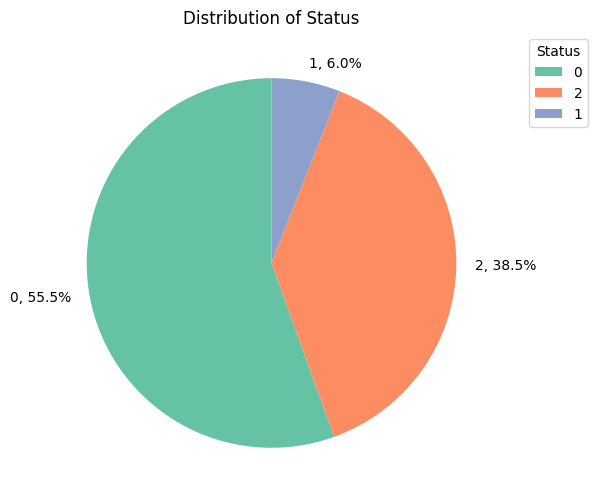

In [49]:
# Counting the observations for each category
status_counts = df[LABEL].value_counts()
labels = status_counts.index
sizes = status_counts.values

# Calculating the percentage of each category
percentages = 100.*sizes/sizes.sum()

# Creating the pie chart with percentages in the labels
plt.figure(figsize=(10, 6))
plt.pie(sizes, labels=[f"{l}, {s:.1f}%" for l, s in zip(labels, percentages)], startangle=90)
plt.gca().set_aspect("equal")
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1), labels=labels, title=LABEL)
plt.title(f"Distribution of {LABEL}")
plt.show()

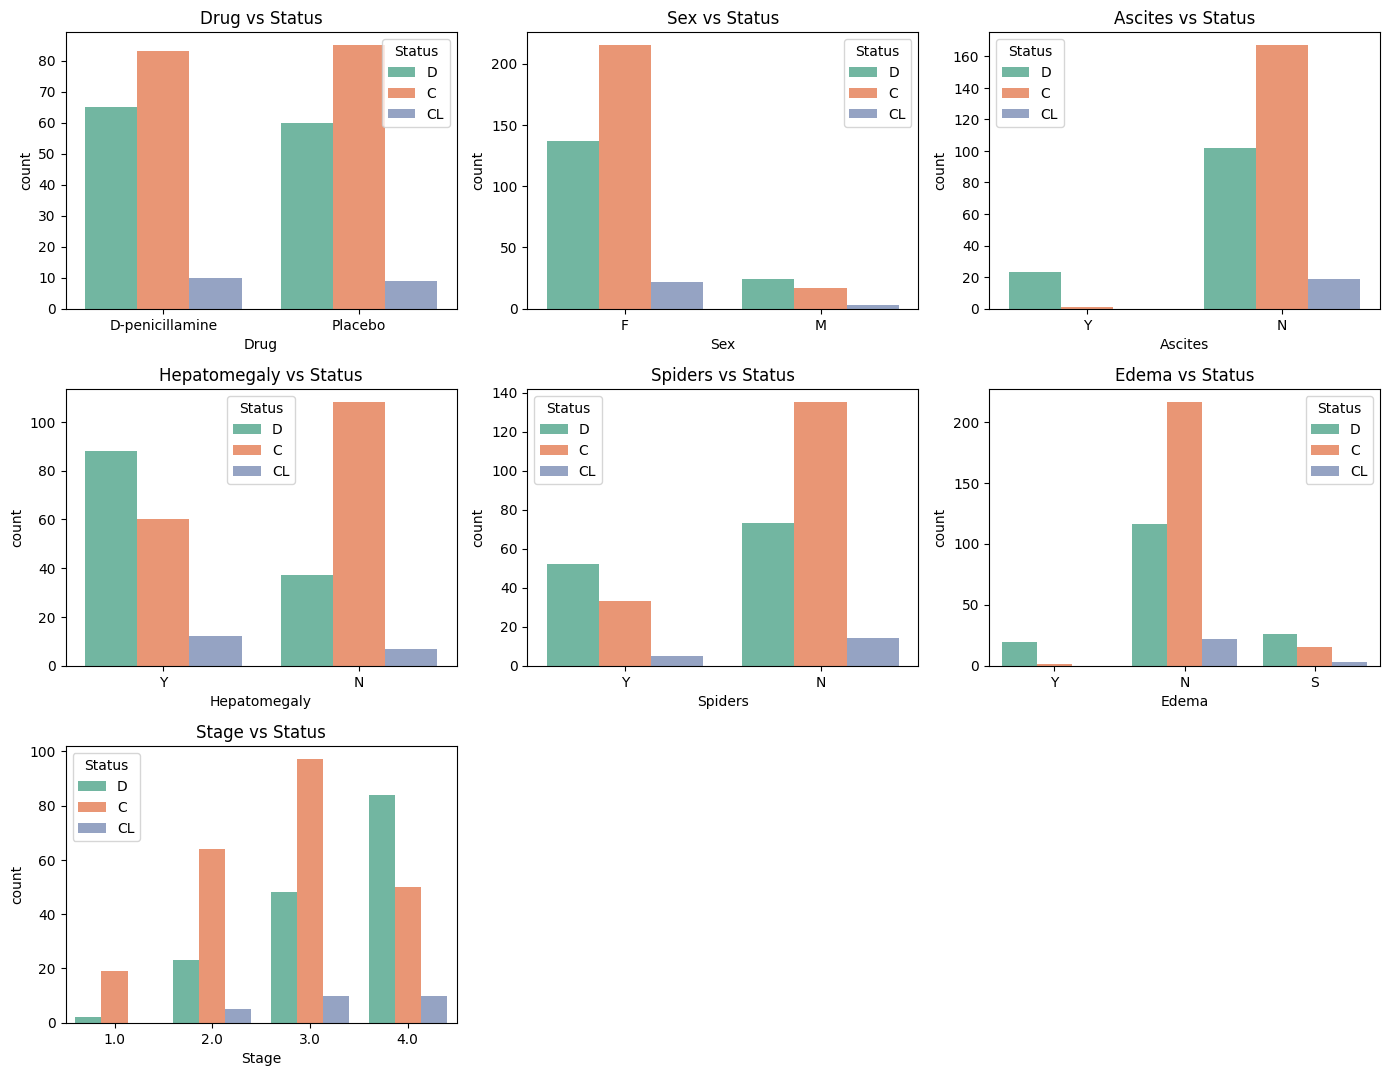

In [52]:
plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(len(CAT_FEATS) // 2 + 1, 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=df)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()

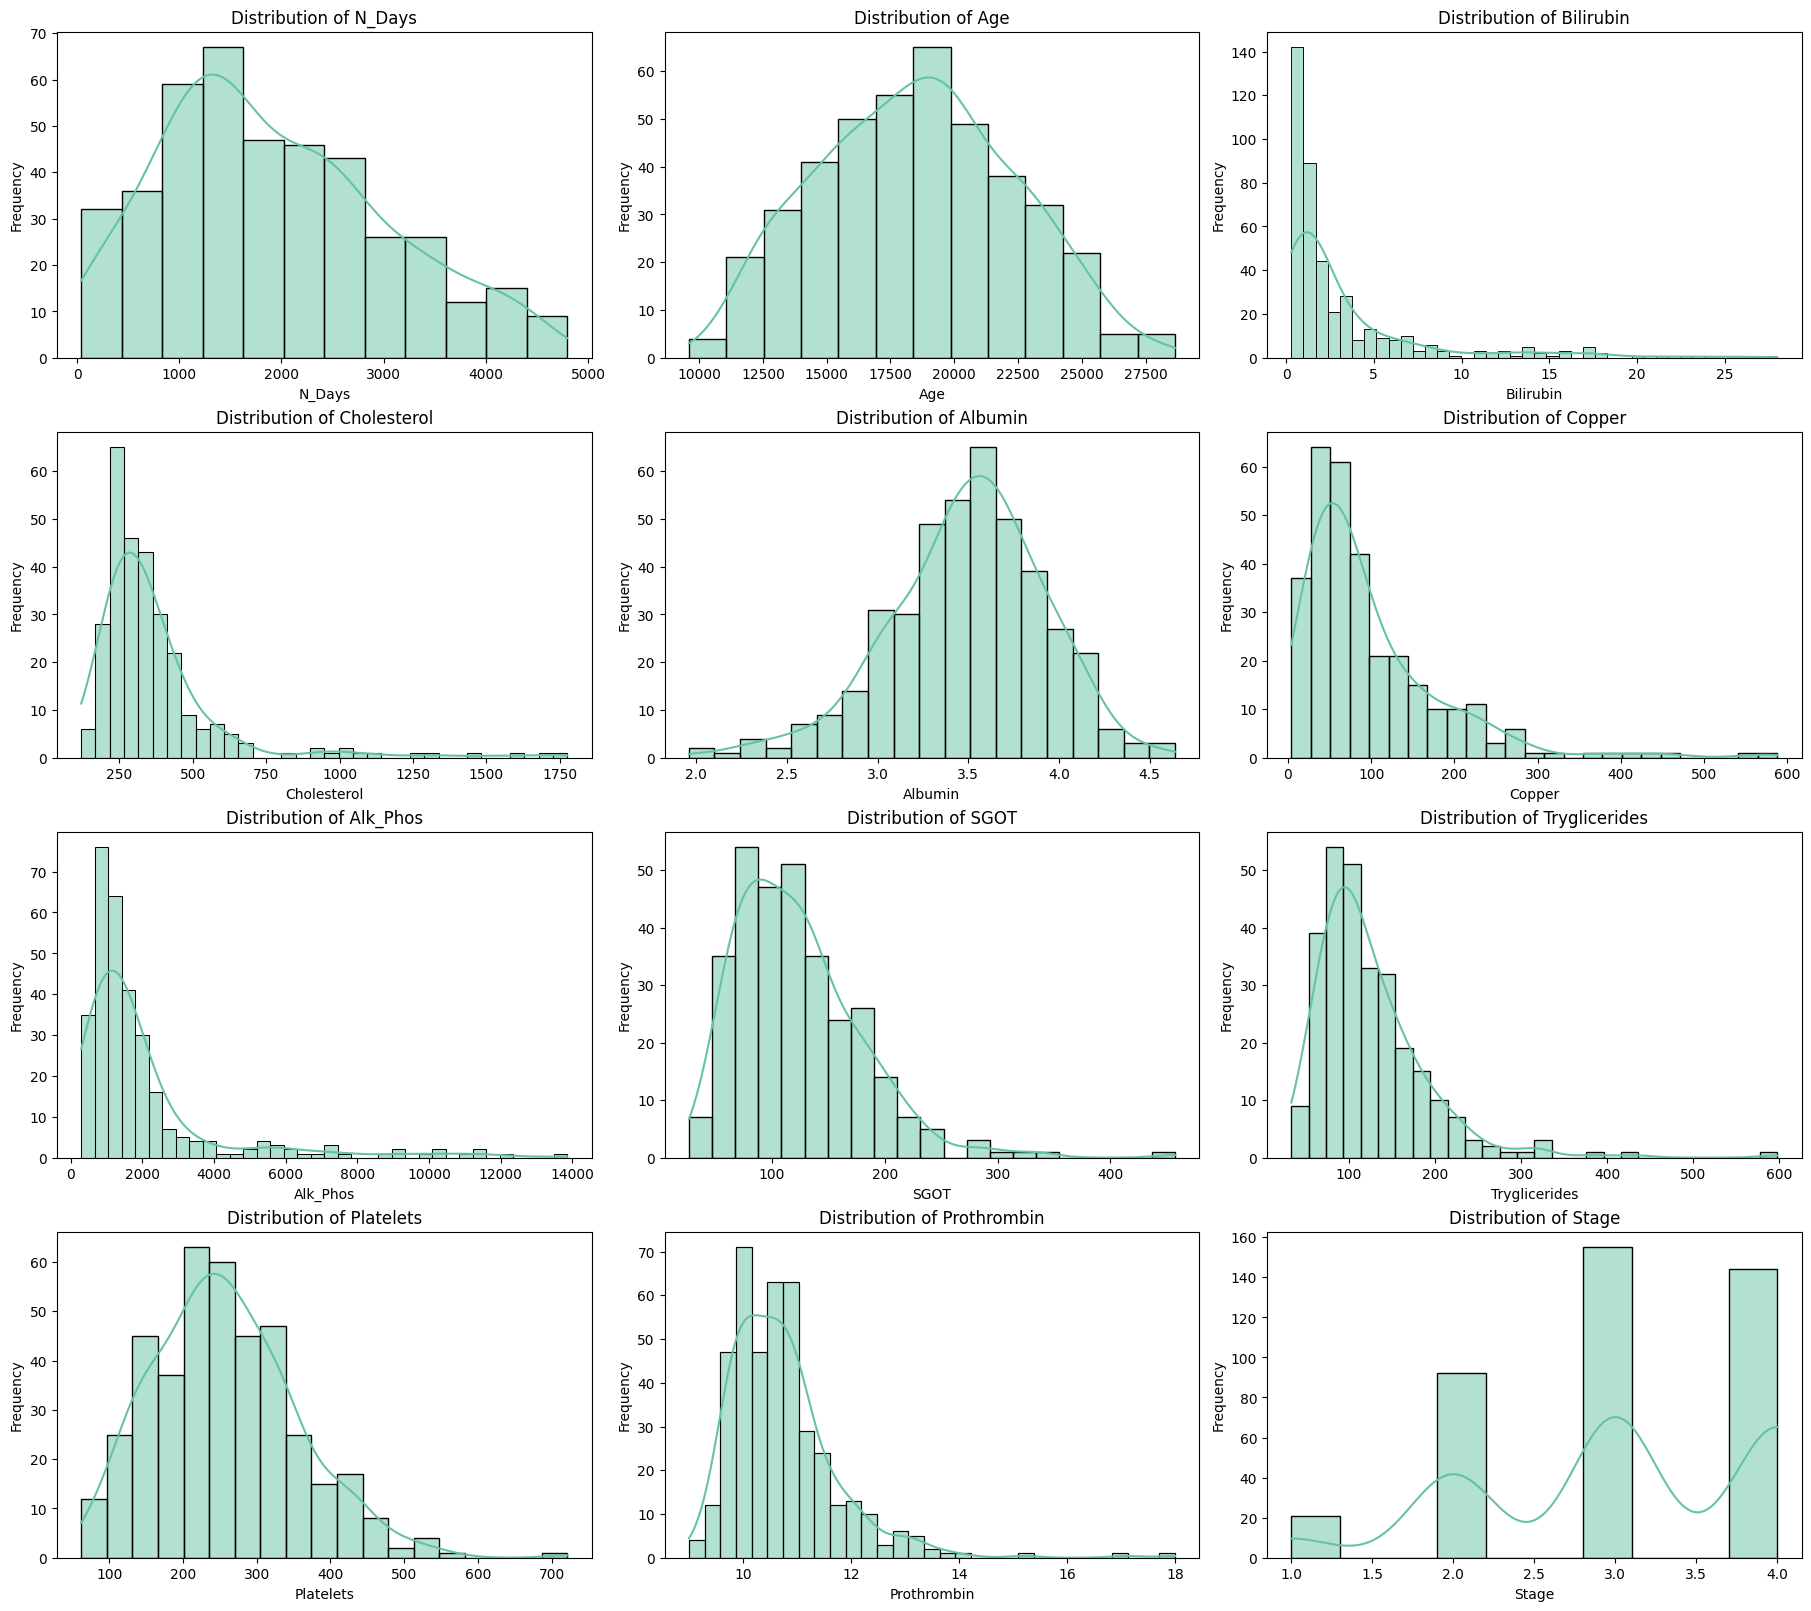

In [19]:
# Histograms to visualize distributions (skip id) [in subplots]

# for i in df.select_dtypes(include=[np.number]).columns:
#     if i != 'ID':
#         plt.figure(figsize=(8,4))
#         sns.histplot(df[i].dropna(), kde=True)
#         plt.title(f'Distribution of {i}')
#         plt.xlabel(i)
#         plt.ylabel('Frequency')
#         plt.show()

cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "ID"]
n = len(cols)

# layout
ncols = 3  # change if you want (e.g., 2 or 4)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)  # flatten in case it's 2D

for ax, col in zip(axes, cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

# turn off any unused axes
for ax in axes[len(cols):]:
    ax.axis("off")

plt.show()

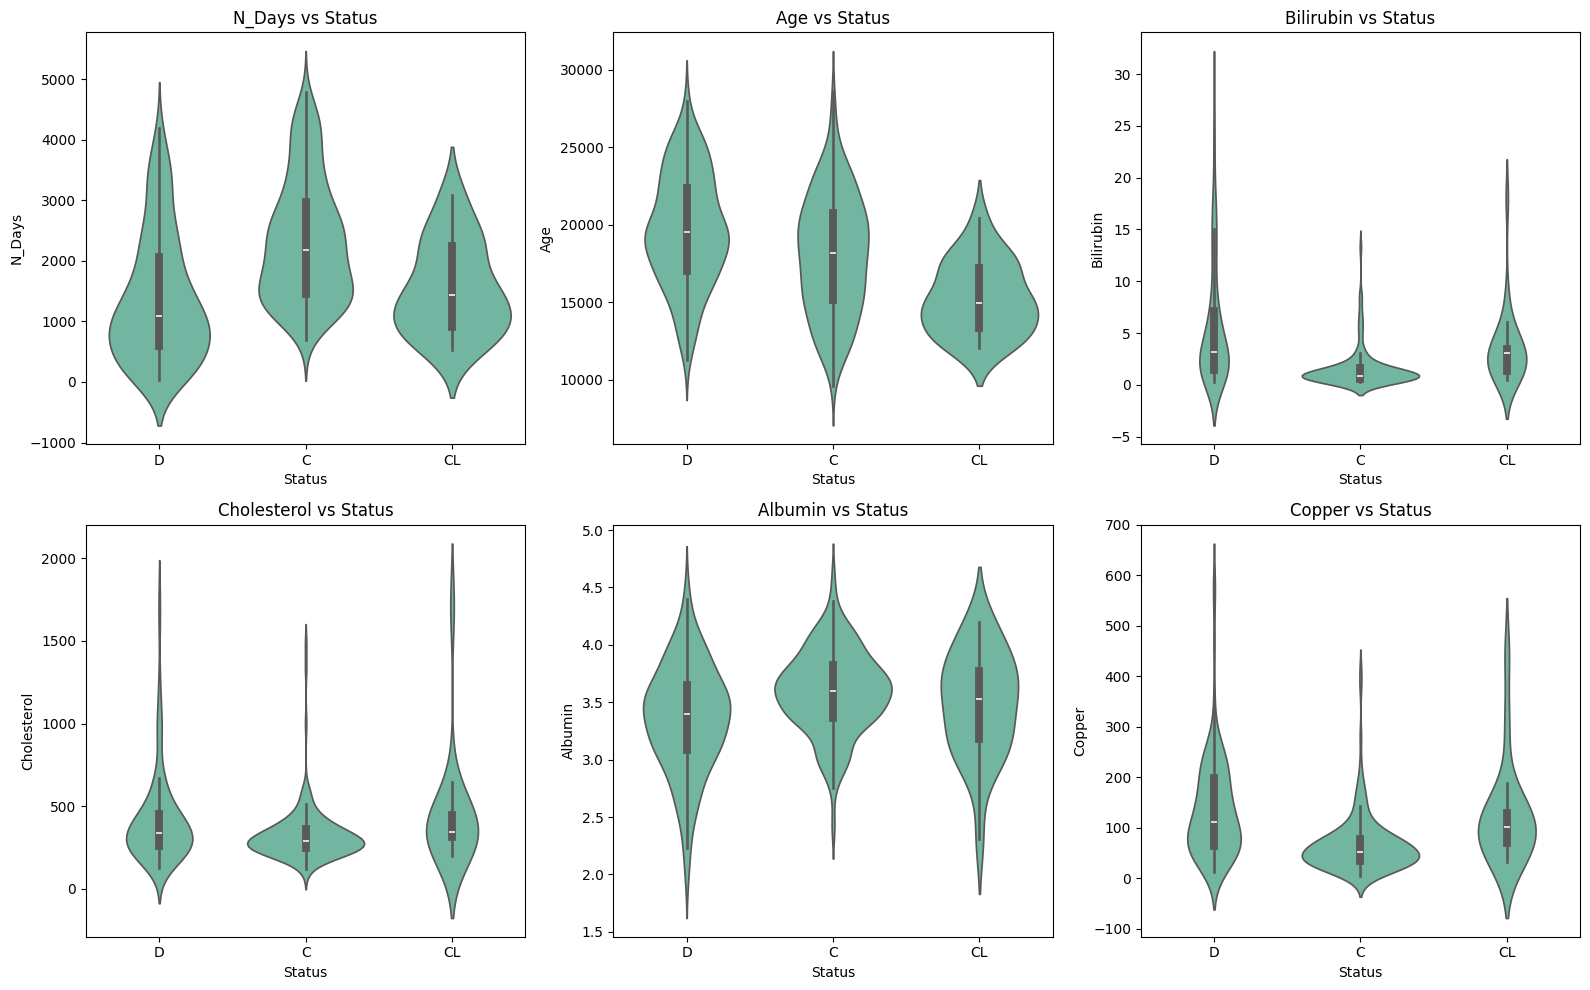

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, ax in enumerate(axes.flatten()):
    sns.violinplot(x=LABEL, y=NUM_FEATS[i], data=df, ax=ax)
    # Set x ticks to be the original labels (inverse transform)
    ax.set_title(f"{NUM_FEATS[i]} vs {LABEL}")
plt.tight_layout()
plt.show()

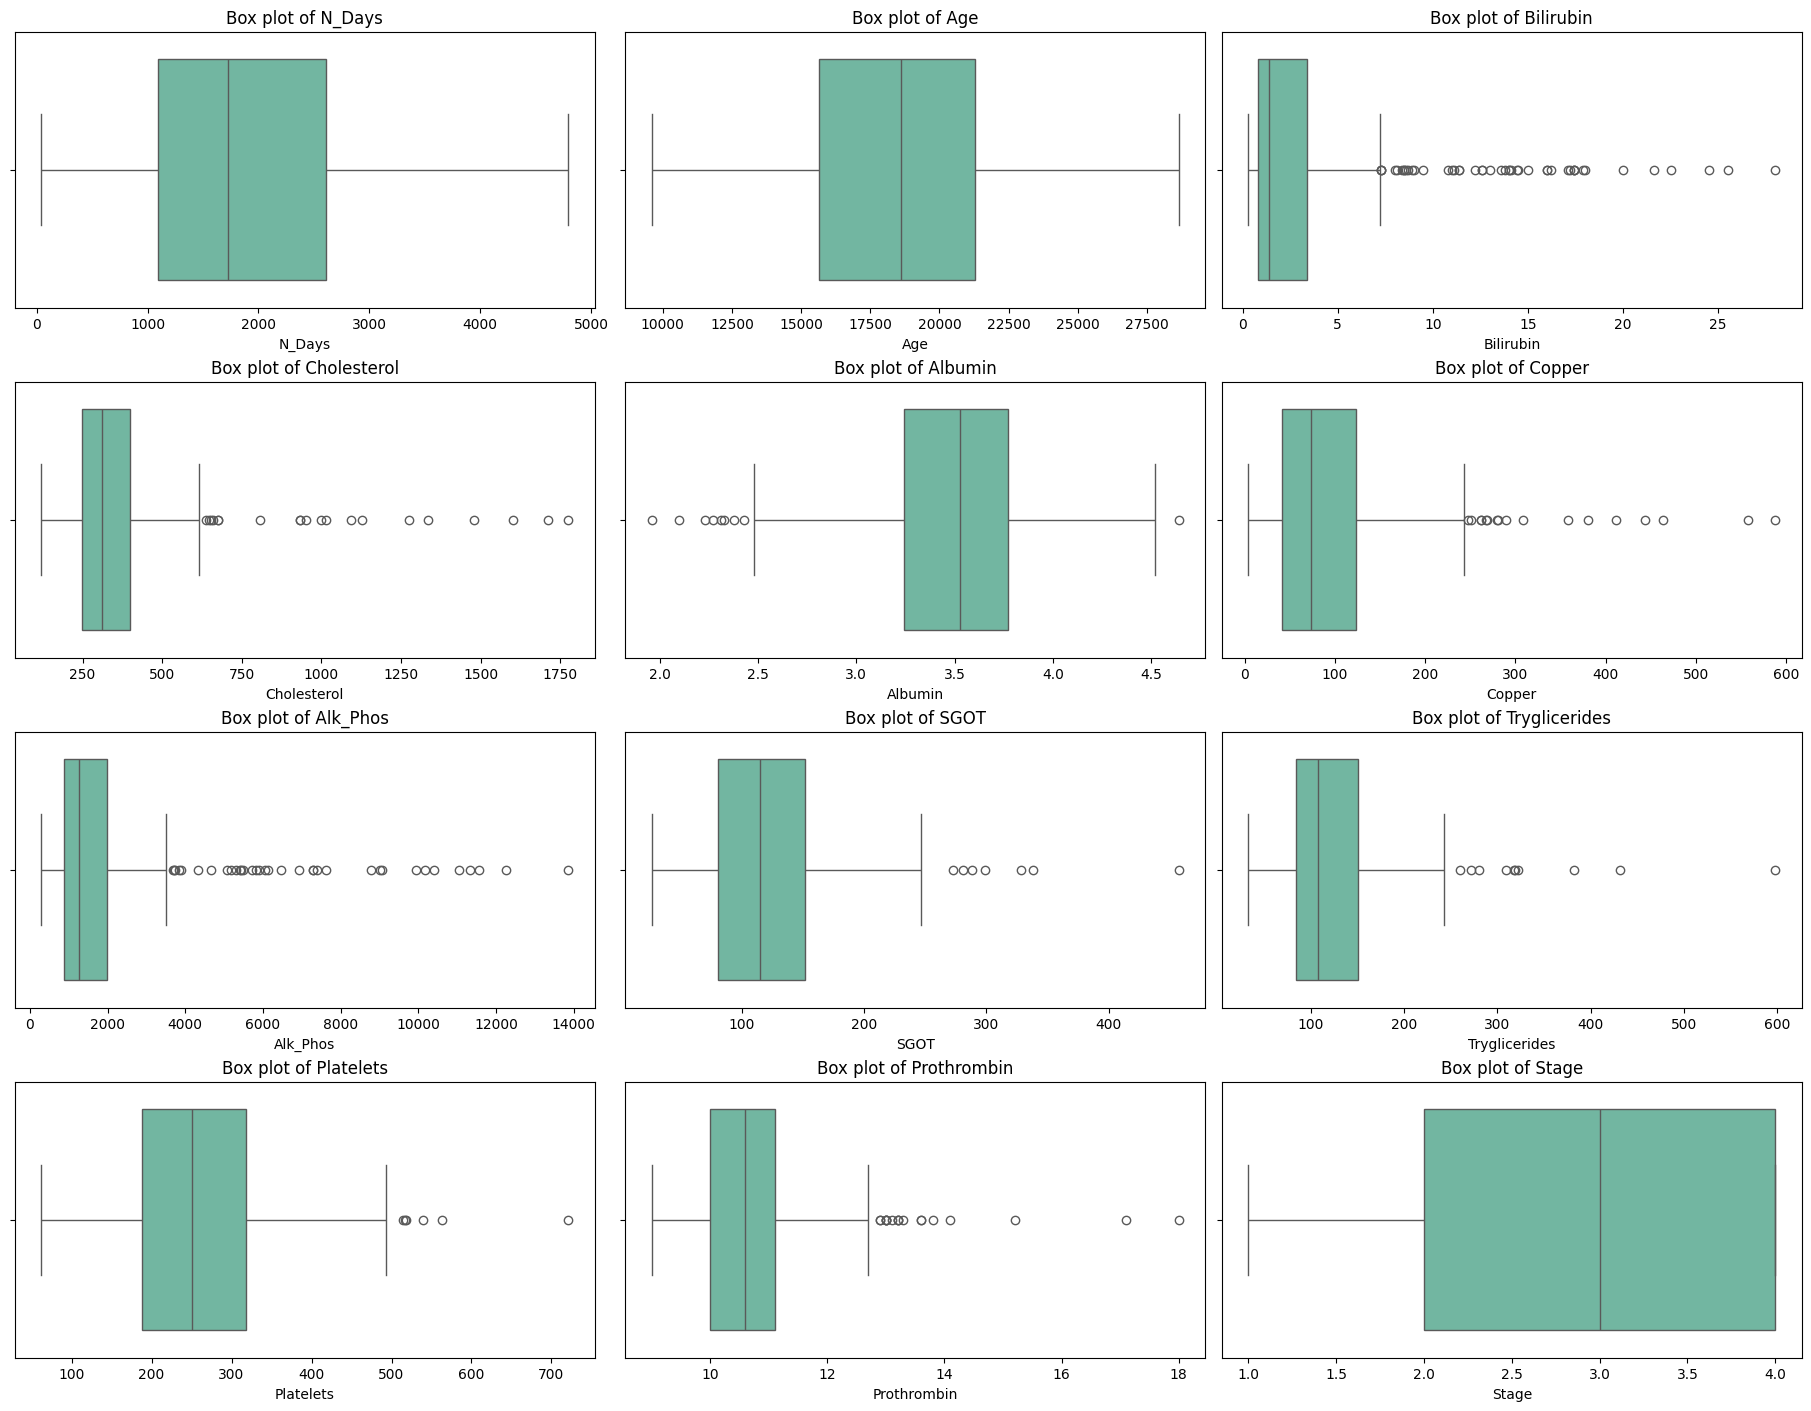

In [21]:
# Box plots to identify outliers

# Single box plot per numerical column
# for i in df.select_dtypes(include=[np.number]).columns:
#     if i != 'ID':
#         plt.figure(figsize=(8,4))
#         sns.boxplot(x=df[i])
#         plt.title(f'Box plot of {i}')
#         plt.xlabel(i)
#         plt.show()

cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != "ID"]
n = len(cols)

ncols = 3  # change to 2/4/etc.
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3.5*nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("")  # boxplot doesn't need y label here

# hide unused subplots
for ax in axes[len(cols):]:
    ax.axis("off")

plt.show()

A scatterplot is the fastest way to see whether two variables move together, whether the relationship is linear 
or not, and whether outliers / groups / heteroscedasticity exist.

As x increases, does y tend to increase or decrease?
* Upward slope → positive association
* Downward slope → negative association
* No slope / blob → little direct association

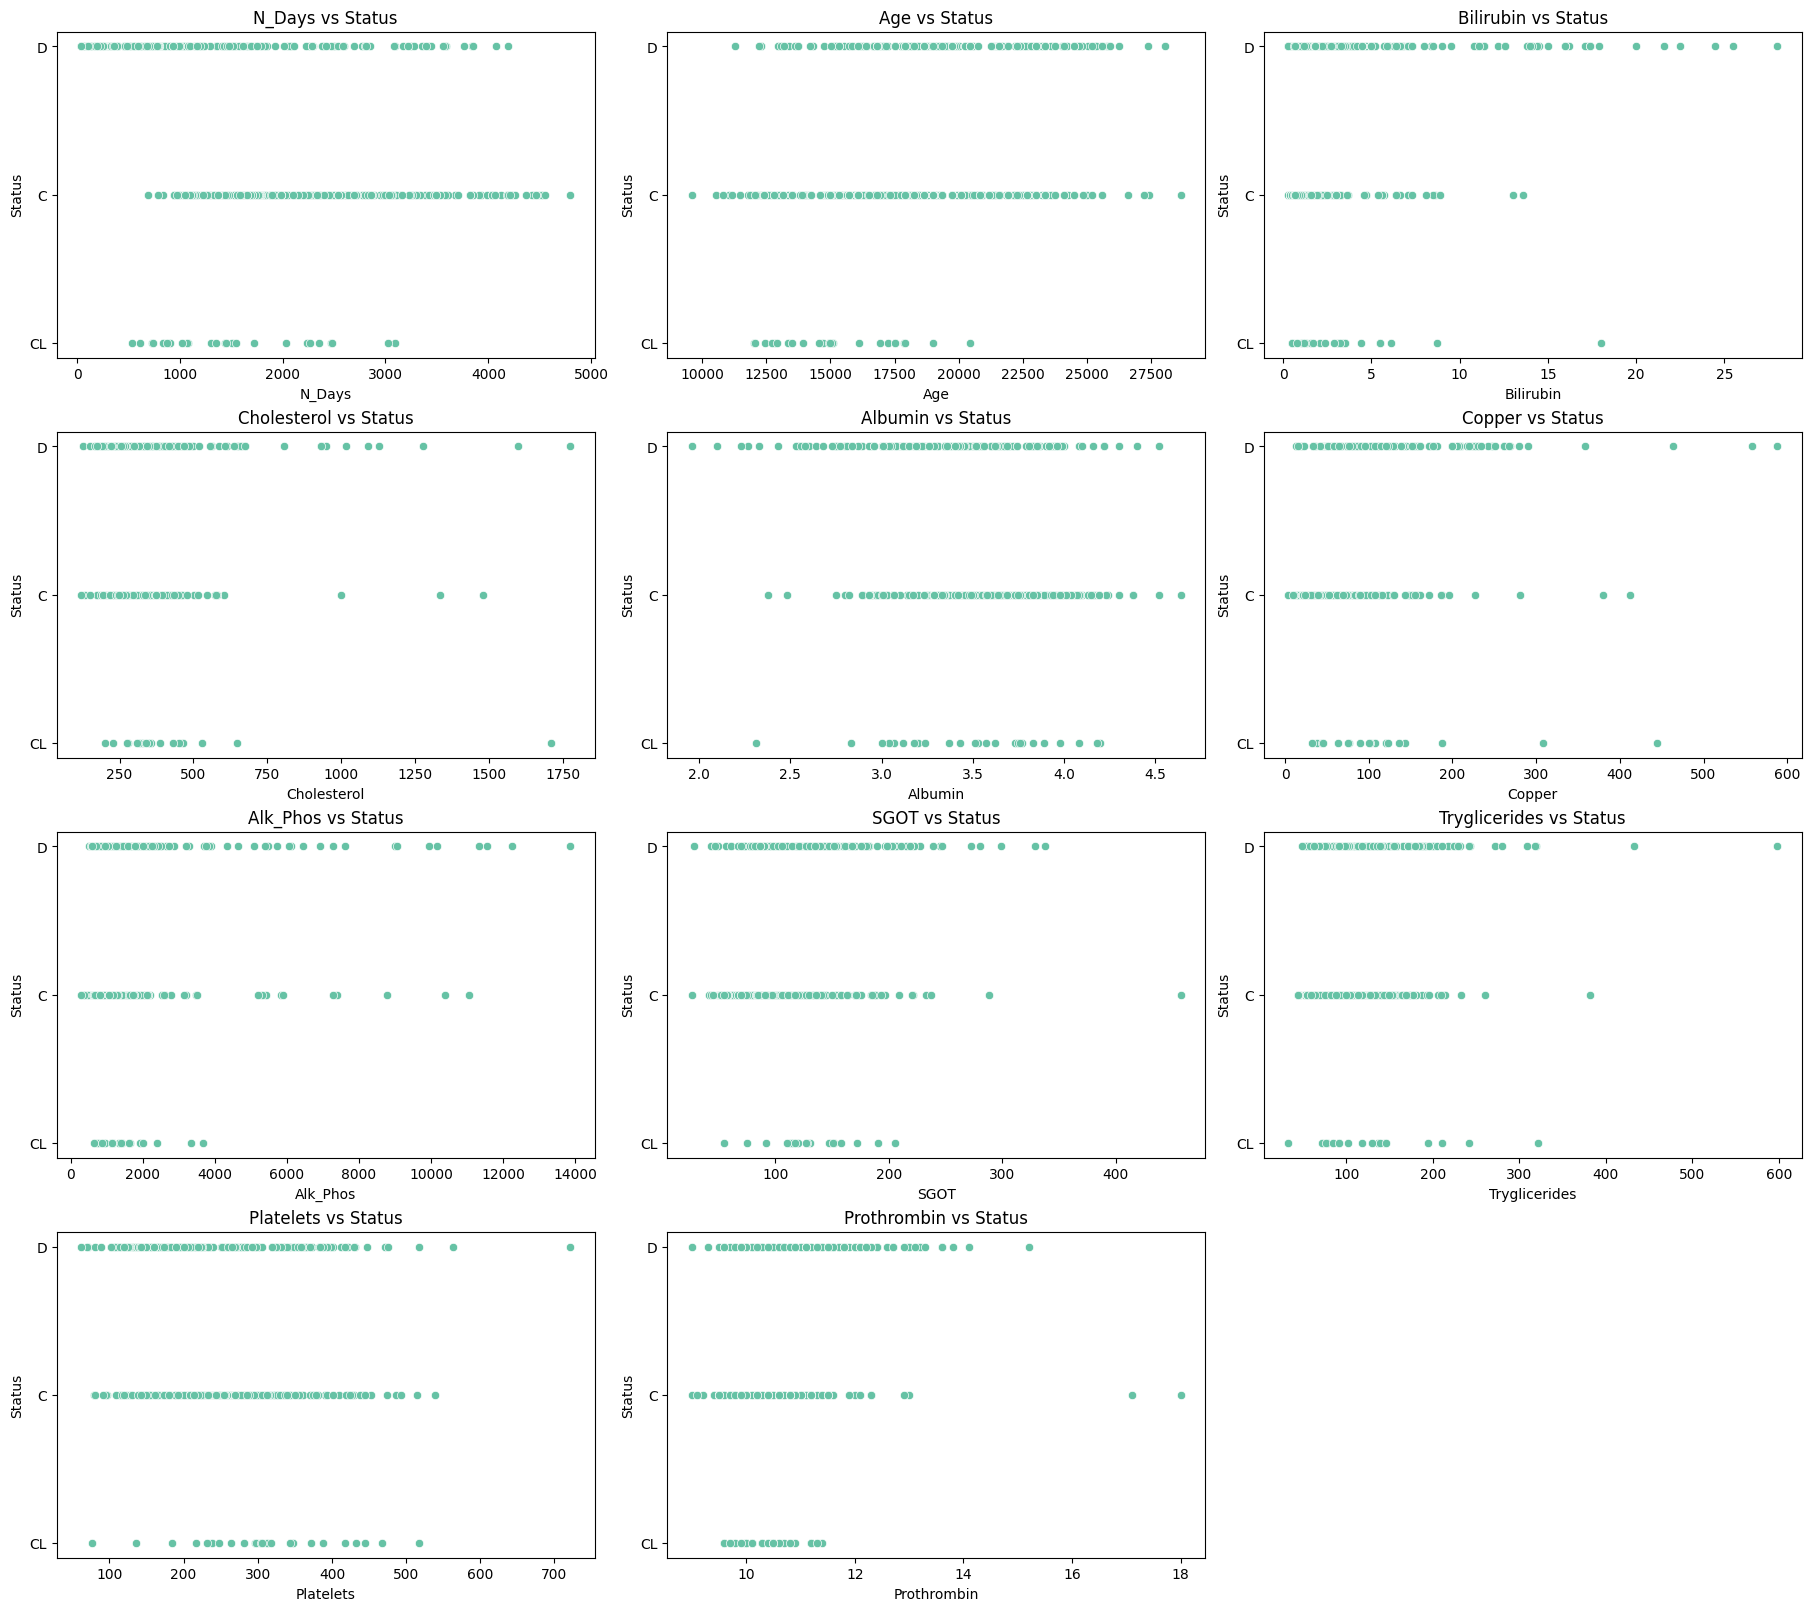

In [22]:
# Scatter plots to identify relationships between numerical features (target column TARGET_COLUMN)
# Numeric columns, excluding 'Stage' (and optionally the target itself)
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if "Stage" in numerical_cols:
    numerical_cols.remove("Stage")
if LABEL in numerical_cols:
    numerical_cols.remove(LABEL)

# for col in numerical_cols:
#     plt.figure(figsize=(8,4))
#     sns.scatterplot(x=df[col], y=df[TARGET_COLUMN])
#     # sns.stripplot(x=df[TARGET_COLUMN], y=df[col], jitter=True, alpha=0.5)
#     plt.title(f'Scatter plot of {col} vs {TARGET_COLUMN}')
#     plt.xlabel(col)
#     plt.ylabel(TARGET_COLUMN)
#     plt.show()


n = len(numerical_cols)

ncols = 3  # change as you like
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4*nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numerical_cols):
    sns.scatterplot(x=df[col], y=df[LABEL], ax=ax)
    ax.set_title(f"{col} vs {LABEL}")
    ax.set_xlabel(col)
    ax.set_ylabel(LABEL)

# hide unused subplots
for ax in axes[len(numerical_cols):]:
    ax.axis("off")

plt.show()

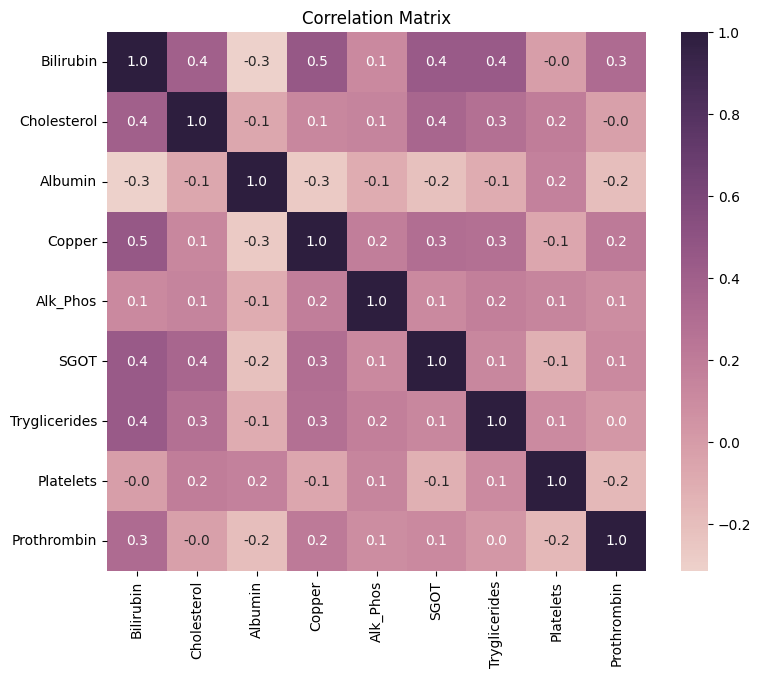

In [23]:
# Correlation matrix
plt.figure(figsize=(9,7))
num_df = df.select_dtypes(include=[np.number])

num_df.drop(columns=['ID'], inplace=True, errors='ignore')
num_df.drop(columns=['Stage'], inplace=True, errors='ignore')  
num_df.drop(columns=['N_Days'], inplace=True, errors='ignore')
num_df.drop(columns=['Age'], inplace=True, errors='ignore')

correlation_matrix = num_df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".1f", square=True, cmap=sns.cubehelix_palette(as_cmap=True))   # cmap="crest"
plt.title('Correlation Matrix')
plt.show()

### No relatively high correlation - no action taken.
There are no highly correlated features. However, we can see a medium positive correlation between *Copper* and *Bilirubin* and a medium negative correlation between Albumin and Bilirubin. This is expected since Copper and Bilirubin are both related to liver function (especially in presence of liver disfunction). Also, Albumin and Bilirubin are negatively correlated since Albumin is a protein produced by the liver and Bilirubin is a waste product of the breakdown of red blood cells.

# Missing value treatment

## The general medical range for the features

**All units match the dataset** documentation.

**Dataset documentation:** https://onlinelibrary.wiley.com/doi/epdf/10.1002/9781118150672.app4

Other unmentioned feature have **binary values** (Sex, Ascites, Hepatomegaly, Spiders, Edema)

* **Bilirubin:** 0.1 to 1.2 mg/dl
* **Cholesterol:** 125 to 200 mg/dl
* **Albumin:** 3.4 to 5.4 gm/dl
* **Copper:** 10-30 ug/day
* **Alkaline Phosphatase:** 40 to 129 U/litre.
* **SGOT:** 8 to 45 U/L
* **Triglycerides:** 48.68 to 168.15 mg/dL
* **Platelet:** 150 to 400 unit
* **Prothrombin Time:** 11 to 13.5 seconds.

### Sources:
* Copper: [myupchar](https://www.myupchar.com/en/test/copper-urine#copper-urine-test-results-and-normal-range), [mountsinai](https://www.mountsinai.org/health-library/tests/24-hour-urine-copper-test)
* Bilirubin: [Mayo_Clinic](https://www.mayoclinic.org/tests-procedures/liver-function-tests/about/pac-20394595)
* Cholesterol: [Mayo_Clinic](https://www.mayoclinic.org/tests-procedures/cholesterol-test/about/pac-20384601)
* Albumin: [Mountsinai](https://www.mountsinai.org/health-library/tests/albumin-blood-serum-test)
* Alk_Phos: [Mountsinai](https://www.mountsinai.org/health-library/tests/alp-blood-test)
* SGOT: [Healthline](https://www.healthline.com/health/sgot-test#results)
* Tryglicerides: [Mountsinai](https://www.mayoclinic.org/diseases-conditions/high-blood-cholesterol/in-depth/triglycerides/art-20048186)
* Platelets: [Mountsinai](https://www.mayoclinic.org/tests-procedures/complete-blood-count/about/pac-20384919)
* Prothrombin: [Mountsinai](https://www.mayoclinic.org/tests-procedures/prothrombin-time/about/pac-20384661)

In [24]:
# Null count check
df.isnull().sum()

N_Days             0
Status             0
Drug             106
Age                0
Sex                0
Ascites          106
Hepatomegaly     106
Spiders          106
Edema              0
Bilirubin          0
Cholesterol      134
Albumin            0
Copper           108
Alk_Phos         106
SGOT             106
Tryglicerides    136
Platelets         11
Prothrombin        2
Stage              6
dtype: int64

### Imputing missing categories using catboost

In [25]:
def iterative_catboost_impute_categoricals(
    df: pd.DataFrame,
    categorical_columns: list[str],
    exclude_columns: list[str] | None = None,
    max_iter: int = 10,
    random_seed: int = 42,
    base_params: dict | None = None,
):
    if exclude_columns is None:
        exclude_columns = []

    work = df.copy()

    # Only impute categorical columns that actually have missing (checking again)
    cat_cols = [c for c in categorical_columns if c in work.columns and work[c].isna().any()]
    if not cat_cols:
        return work

    # Force pandas dtypes so CatBoost doesn't treat them as numeric 
    # Make all declared categorical cols into string (keepiong NaN as NaN)
    for c in categorical_columns:
        if c in work.columns:
            work[c] = work[c].astype("string")

    # Store original missing indices
    missing_idx = {c: work.index[work[c].isna()] for c in cat_cols}

    # Fill NaNs with per column placeholder
    for c in cat_cols:
        work[c] = work[c].fillna(f"__MISSING__{c}")

    params0 = {
        "depth": 6,
        "learning_rate": 0.1,
        "l2_leaf_reg": 0.7,
        "random_strength": 0.2,
        "max_bin": 200,
        "od_wait": 65,
        "one_hot_max_size": 70,
        "grow_policy": "Depthwise",
        "bootstrap_type": "Bayesian",
        "od_type": "Iter",
        "random_seed": random_seed,
        "verbose": False,
    }
    if base_params:
        params0.update(base_params)

    # decide which columns are categorical in X
    def get_cat_feature_names(X: pd.DataFrame, target_col: str) -> list[str]:
        # categorical_columns are categorical by definition (except the current target)
        cat_set = set(categorical_columns) - {target_col}
        # also treat pandas "string" and "category" as categorical
        for col in X.columns:
            if str(X[col].dtype) in ("string", "category", "object"):
                cat_set.add(col)
        return [c for c in X.columns if c in cat_set]

    for _ in tqdm(range(max_iter), desc="Imputation iterations"):
        for target_col in cat_cols:
            idx_miss = missing_idx[target_col]
            if len(idx_miss) == 0:
                continue

            idx_train = work.index.difference(idx_miss)

            drop_cols = [target_col] + exclude_columns
            X_train = work.loc[idx_train].drop(columns=drop_cols, errors="ignore")
            y_train = work.loc[idx_train, target_col].astype(str)

            X_pred = work.loc[idx_miss].drop(columns=drop_cols, errors="ignore")

            cat_feature_names = get_cat_feature_names(X_train, target_col)

            n_classes = y_train.nunique(dropna=False)
            params = dict(params0)
            if n_classes <= 2:
                params["loss_function"] = "Logloss"
                params["eval_metric"] = "Logloss"
            else:
                params["loss_function"] = "MultiClass"
                params["eval_metric"] = "MultiClass"

            model = CatBoostClassifier(**params)

            model.fit(X_train, y_train, cat_features=cat_feature_names)

            preds = np.asarray(model.predict(X_pred)).ravel().astype(str)
            work.loc[idx_miss, target_col] = preds

    # removing sentinel if anything remains
    for c in cat_cols:
        work.loc[work[c] == f"__MISSING__{c}", c] = np.nan

    return work


In [26]:
# Showing missing percentag in df 
cat_missing = [c for c in CAT_FEATS if df[c].isna().any()]
missing_pct = df[cat_missing].isna().mean().sort_values(ascending=False) * 100
print(missing_pct)

# Impute
df_imputed = iterative_catboost_impute_categoricals(
    df,
    categorical_columns=CAT_FEATS,          
    exclude_columns=[LABEL],      
    max_iter=10,
)

Drug            25.358852
Ascites         25.358852
Hepatomegaly    25.358852
Spiders         25.358852
Stage            1.435407
dtype: float64


Imputation iterations:   0%|          | 0/10 [00:00<?, ?it/s]

In [27]:
# before
before_pct = df[CAT_FEATS].isna().mean().mul(100)

# after
after_pct = df_imputed[CAT_FEATS].isna().mean().mul(100)

compare = (
    pd.concat([before_pct, after_pct], axis=1, keys=["Before %", "After %"])
      .sort_values("Before %", ascending=False)
)

display(compare)

,Before %,After %
Drug,25.358852,0.0
Ascites,25.358852,0.0
Hepatomegaly,25.358852,0.0
Spiders,25.358852,0.0
Stage,1.435407,0.0
Sex,0.000000,0.0
Edema,0.000000,0.0


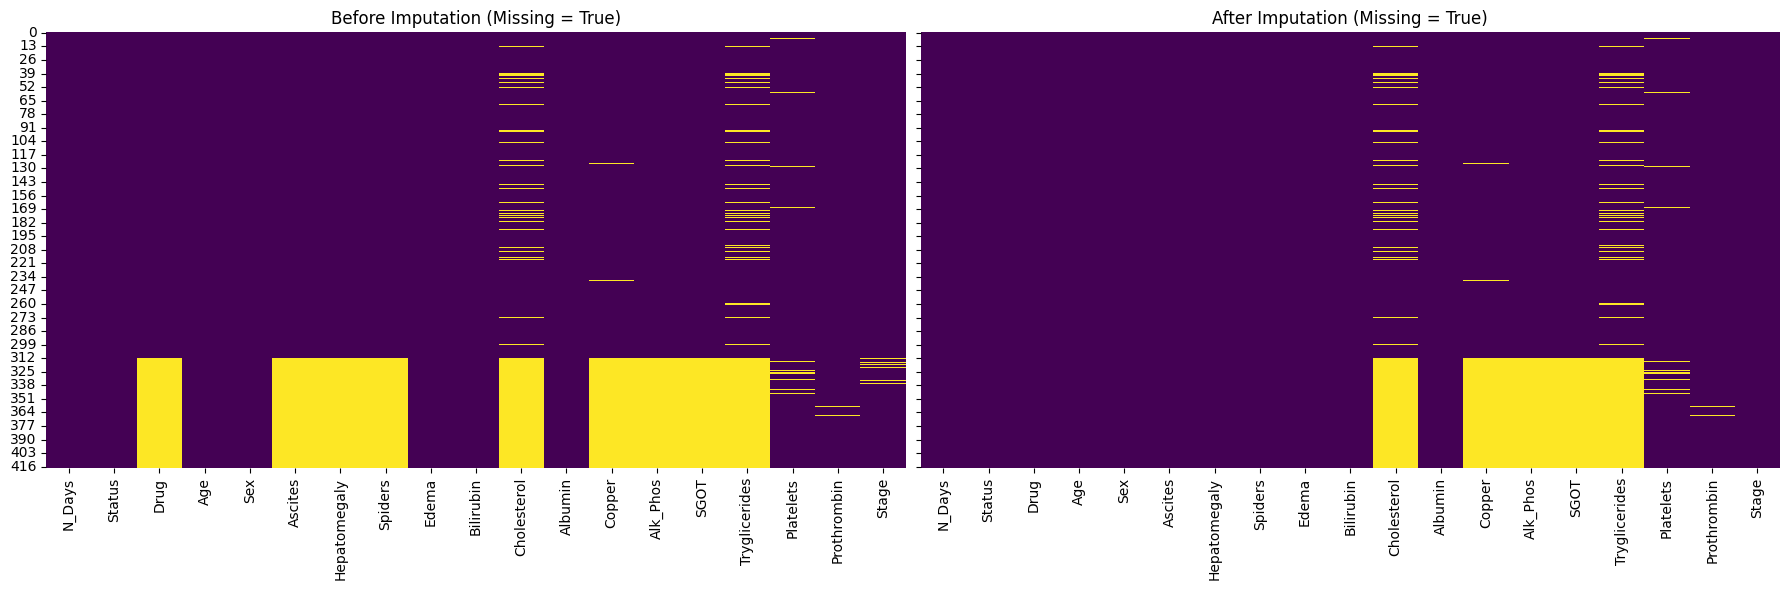

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

sns.heatmap(df.isnull(), cbar=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Before Imputation (Missing = True)")

sns.heatmap(df_imputed.isnull(), cbar=False, cmap="viridis", ax=axes[1])
axes[1].set_title("After Imputation (Missing = True)")

plt.tight_layout()
plt.show()


### Filling numerical nan values

In [29]:
def rmse(a, b):
    a = np.asarray(a).ravel()
    b = np.asarray(b).ravel()
    return np.sqrt(mean_squared_error(a, b))

def iterative_catboost_impute_numericals(
    df: pd.DataFrame,
    numerical_columns: list[str],
    categorical_columns: list[str] | None = None,
    exclude_columns: list[str] | None = None,
    max_iter: int = 5,
    cb_params: dict | None = None,
    plot_rmse: bool = True,
):
    # Iteratively imputing missing numeric values using CatBoostRegressor.
    # For each numeric feature with missing values:
    #   [*] Train on rows where feature is known
    #   [*] Predict for rows where feature is missing
    #   [*] Repeat for max_iter iterations
    #   [*] Track RMSE between new vs previous predictions per iteration
    # returns new DataFrame (imputed).

    work = df.copy()

    if exclude_columns is None:
        exclude_columns = []

    if categorical_columns is None:
        categorical_columns = []

    # only impute numeric cols that actually exist and have missing
    num_cols = [c for c in numerical_columns if c in work.columns and work[c].isna().any()]
    if not num_cols:
        return work

    # storing original missing indices per numeric column
    missing_idx = {c: work.index[work[c].isna()] for c in num_cols}

    # initial fill using mean
    for c in num_cols:
        work[c] = work[c].fillna(work[c].mean())

    # cat boost parameters
    params0 = {
        "iterations": 500,
        "depth": 6,
        "learning_rate": 0.02,
        "l2_leaf_reg": 0.5,
        "random_strength": 0.2,
        "max_bin": 150,
        "od_wait": 80,
        "bootstrap_type": "Bayesian",
        "od_type": "IncToDec",
        "loss_function": "RMSE",
        "eval_metric": "RMSE",
        "random_seed": 42,
        "verbose": False,
    }
    if cb_params:
        params0.update(cb_params)

    # tracking how predictions change over iterations
    rmse_history = {c: [] for c in num_cols}

    # precomputing which input cols are categorical for CatBoost
    def cat_feature_names(X: pd.DataFrame) -> list[str]:
        cat_set = set(categorical_columns)
        for col in X.columns:
            if str(X[col].dtype) in ("object", "string", "category"):
                cat_set.add(col)
        return [c for c in X.columns if c in cat_set]

    for _ in tqdm(range(max_iter), desc="Imputation iterations (numeric)"):
        for target_col in num_cols:
            idx_miss = missing_idx[target_col]
            if len(idx_miss) == 0:
                continue

            idx_train = work.index.difference(idx_miss)

            # y_prev = last iteration imputed values for stability RMSE
            y_prev = work.loc[idx_miss, target_col].copy()

            drop_cols = [target_col] + exclude_columns
            X_train = work.loc[idx_train].drop(columns=drop_cols, errors="ignore")
            y_train = work.loc[idx_train, target_col]

            X_pred = work.loc[idx_miss].drop(columns=drop_cols, errors="ignore")

            model = CatBoostRegressor(**params0)
            model.fit(X_train, y_train, cat_features=cat_feature_names(X_train))

            y_new = model.predict(X_pred)
            work.loc[idx_miss, target_col] = y_new

            rmse_history[target_col].append(rmse(y_new, y_prev))

    # how stable are predictions becoming?
    if plot_rmse:
        plt.figure(figsize=(10, 5))
        for col, values in rmse_history.items():
            plt.plot(range(1, len(values) + 1), values, label=col)
        plt.xlabel("Iteration")
        plt.ylabel("RMSE (new vs previous imputed values)")
        plt.title("Stabilization of numeric imputations across iterations")
        plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

    return work


Tryglicerides    32.535885
Cholesterol      32.057416
Copper           25.837321
Alk_Phos         25.358852
SGOT             25.358852
Platelets         2.631579
Prothrombin       0.478469
dtype: float64


Imputation iterations (numeric):   0%|          | 0/5 [00:00<?, ?it/s]

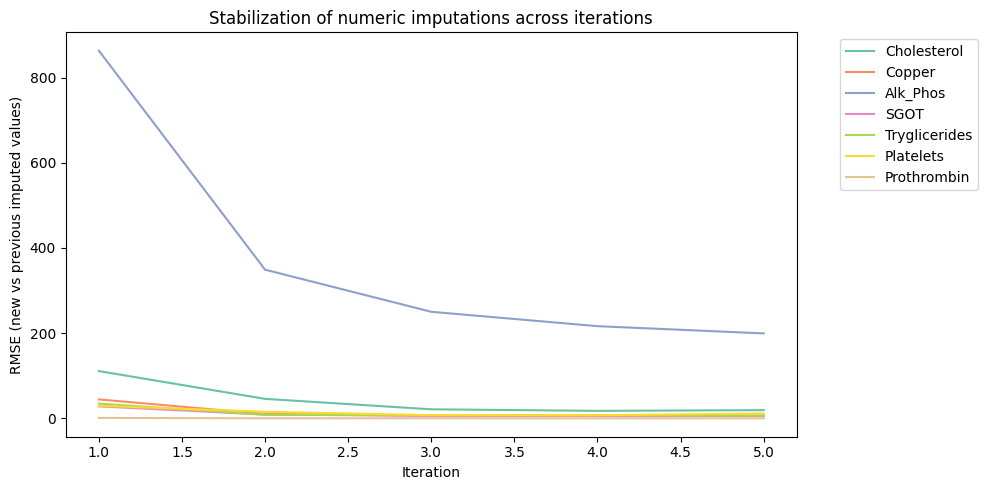

In [30]:
# numeric imputation
missing_num = [c for c in NUM_FEATS if df[c].isna().any()]
missing_num_pct = df[missing_num].isna().mean().mul(100).sort_values(ascending=False)
print(missing_num_pct)

df_imputed_num = iterative_catboost_impute_numericals(
    df=df_imputed,                 
    numerical_columns=NUM_FEATS,
    categorical_columns=CAT_FEATS,
    exclude_columns=[LABEL], 
    max_iter=5,
    plot_rmse=True
)

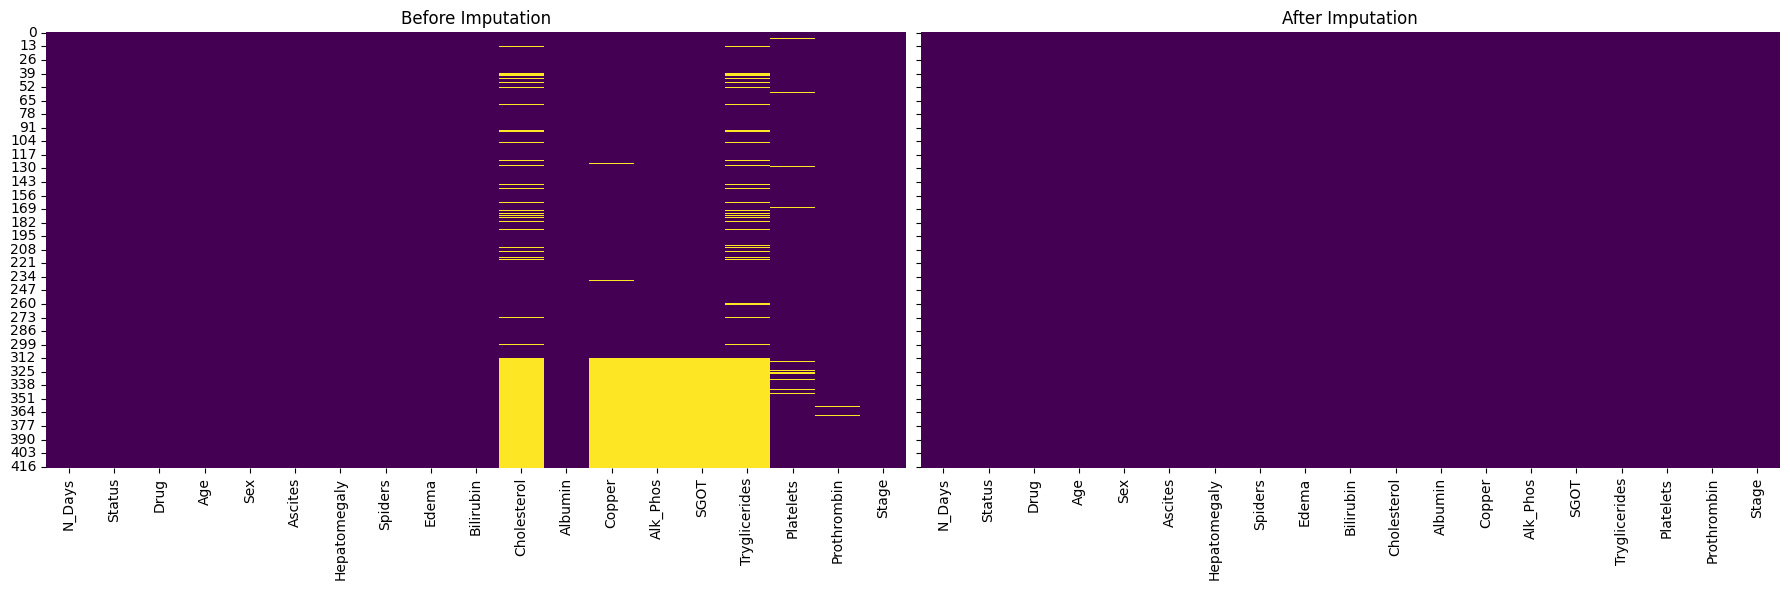

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

sns.heatmap(df_imputed.isnull(), cbar=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Before Imputation")

sns.heatmap(df_imputed_num.isnull(), cbar=False, cmap="viridis", ax=axes[1])
axes[1].set_title("After Imputation")

plt.tight_layout()
plt.show()

In [32]:
df = df_imputed_num.copy()

### Notes:
![image.png](./images/encoding_notes.png)

We will use :
* One-Hot Encoding: `Edema`
* Ordinal Encoding: `Stage`
* Binary Encoding: `Drug`, `Sex`, `Ascites`, `Hepatomegaly`, `Spiders`
* Label Encoding: `Status` (target variable)

In [33]:
# Encoding the label
label_encoder = LabelEncoder()
df[LABEL] = label_encoder.fit_transform(df[LABEL])

In [34]:
# Features encoding
encoders = {
    'Drug': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, categories=[['Placebo', 'D-penicillamine']]),
    'Sex': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    'Ascites': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    'Hepatomegaly': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    'Spiders': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    # 'Edema': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, categories=[['N', 'S', 'Y']]),
    'Edema': OneHotEncoder(),
    'Stage': OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
}

In [35]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

fitted_encoders = {}

for feat, enc in encoders.items():
    if feat not in df.columns:
        continue

    # Ordinal
    if isinstance(enc, OrdinalEncoder):
        x = df[[feat]].astype("string")        
        vals = enc.fit_transform(x)              
        df[feat] = vals.ravel().astype("int32")  
        fitted_encoders[feat] = enc

    # OneHot
    elif isinstance(enc, OneHotEncoder):
        # make dense output (sklearn version compatible) + ignore unseen
        if hasattr(enc, "sparse_output"):
            enc.set_params(sparse_output=False, handle_unknown="ignore")
        else:
            enc.set_params(sparse=False, handle_unknown="ignore")

        x = df[[feat]].astype("string")
        onehot = enc.fit_transform(x)
        col_names = enc.get_feature_names_out([feat])

        onehot_df = pd.DataFrame(onehot, columns=col_names, index=df.index).astype("int8")
        df = pd.concat([df.drop(columns=[feat]), onehot_df], axis=1)

        fitted_encoders[feat] = enc

In [36]:
print("Encoded DataFrame shape:", df.shape)
print(df.head())

Encoded DataFrame shape: (418, 21)
   N_Days  Status  Drug    Age  Sex  Ascites  Hepatomegaly  Spiders  \
0     400       2     1  21464    0        1             1        1   
1    4500       0     1  20617    0        0             1        1   
2    1012       2     1  25594    1        0             0        0   
3    1925       2     1  19994    0        0             1        1   
4    1504       1     0  13918    0        0             1        1   

   Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos    SGOT  Tryglicerides  \
0       14.5        261.0     2.60   156.0    1718.0  137.95          172.0   
1        1.1        302.0     4.14    54.0    7394.8  113.52           88.0   
2        1.4        176.0     3.48   210.0     516.0   96.10           55.0   
3        1.8        244.0     2.54    64.0    6121.8   60.63           92.0   
4        3.4        279.0     3.53   143.0     671.0  113.15           72.0   

   Platelets  Prothrombin  Stage  Edema_N  Edema_S  Edema_Y  
0

In [37]:
df.to_csv("./data/preprocessed/2_cirrhosis_patient_survival_prediction_preprocessed_df.csv", index=False)

In [38]:
# Lading preprocessed data
df = pd.read_csv("./data/preprocessed/2_cirrhosis_patient_survival_prediction_preprocessed_df.csv")

In [39]:
LABEL = "Status"
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
NUM_FEATS = [x for x in df.columns if x not in CAT_FEATS and x != LABEL]
INP_FEATS = df.drop(LABEL, axis=1).columns.tolist() # original feats

# Running a base model

In [40]:
# Split features/label
X = df.drop(columns=[LABEL])   # LABEL = "Status"
y = df[LABEL]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # keeps class proportions similar in train/test
)

In [46]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000))
])

# start timer
start_time = time.perf_counter()

# training
model.fit(X_train, y_train)

# end timer
train_time = time.perf_counter() - start_time

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy: {:.4f} %".format(acc))
print(f"Training time: {train_time:.6f} seconds")

Accuracy: 0.7381 %
Training time: 0.009478 seconds
